# **Data Science and Machine Learning 1 - Year 4 Portfolio**
## Last.fm KMeans Clustering and Principal Component Analysis Notebook (WIP)

*By Mark Lambert - C00192497 | [LinkedIn](https://www.linkedin.com/in/mark-lambert-27tw721921/) | [GitHub](https://github.com/lambert-27)* | [Personal Email](mailto:marklambert123@gmail.com)

*Lecturer: Ben O'Shaughnessey*

*Submission Date: 27th November 2026*

*Start Date: 2nd November 2026*

---

## Research question

**Do the tracks I have listened to group into clusters based on their Spotify audio features, and does the grouping match the time of day I listened to them?**

The notebook uses ei

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, confusion_matrix
import numpy as np
import seaborn as sns; sns.set()


audio = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
         'instrumentalness', 'liveness', 'valence', 'tempo', 'duration']

plays = pd.read_csv('../datasets/scrobbles.csv')
tracks = pd.read_csv('../datasets/scrobbled_merged_with_hugging_face.csv')

In [19]:
features = ['danceability', 'energy', 'loudness', 'speechiness',
            'acousticness', 'instrumentalness', 'liveness', 'valence']

X = tracks[features].dropna()

In [20]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

CLUSTER_COUNT = 4
kmeans = KMeans(n_clusters=CLUSTER_COUNT, random_state=42)

clusters = kmeans.fit_predict(X_scaled)
X['cluster'] = clusters

In [21]:
cluster_summary = X.groupby("cluster")[X.columns].mean()
print(cluster_summary)

         danceability    energy   loudness  speechiness  acousticness  \
cluster                                                                 
0            0.605672  0.711270  -7.652551     0.058779      0.127623   
1            0.439346  0.726882  -8.244980     0.087492      0.117241   
2            0.375438  0.814224  -6.074948     0.076061      0.050918   
3            0.458624  0.300920 -14.903076     0.064525      0.602942   

         instrumentalness  liveness   valence  cluster  
cluster                                                 
0                0.190915  0.158132  0.640181      0.0  
1                0.324611  0.630000  0.432095      1.0  
2                0.172297  0.162936  0.323580      2.0  
3                0.355091  0.165585  0.253884      3.0  


### Cluster 0 - Upbeat Danceable Tracks
- Cluster 0 has the highest danceability (0.61) and the highest valence (0.64) of any cluster. Energy is high (0.71), acousticness is low (0.13).
- These are the tracks that sound bright, rhythmic and happy. Pop, upbeat rock and dance tracks would likely fall here

### Cluster 1 - Live Recordings
- Cluster 1 is separated almost entirely by one feature: liveness is 0.63, compared to around 0.16 for the other three clusters
- Live albums, gig recordings and anything with a captured audience will land here regardless of genre
- The other features are similar to cluster 2 (high energy, low acousticness), which makes sense, most live recordings are of louder tracks

### Cluster 2 - Loud Energetic Tracks
- Cluster 2 has the highest energy (0.81) and the highest loudness (-6.07) of any cluster. Acousticness is the lowest at 0.05 and valence is on the lower side (0.32)
- These are the heavier tracks, rock, metal and high-intensity electronic music. The loud, non-acoustic and somewhat darker profile matches that description
- This cluster is also the second-largest by count, which fits with as my music taste contains a lot of rock and metal

### Cluster 3 - Quiet Acoustic Tracks
- Cluster 3 has the lowest energy (0.30), the lowest loudness (-14.9) and the highest acousticness (0.60) and instrumentalness (0.36)
- This is the opposite end of the spectrum from cluster 2: quiet, acoustic, instrumental-leaning tracks. Ambient, folk and acoustic singer-songwriter tracks would cluster here
- Combined with the time-of-day table below, this cluster is also the one most likely to show up at night

The clusters are defined by audio features, not by artist, so a single artist can span multiple clusters, a band with both acoustic and heavy tracks will split across clusters 2 and 3


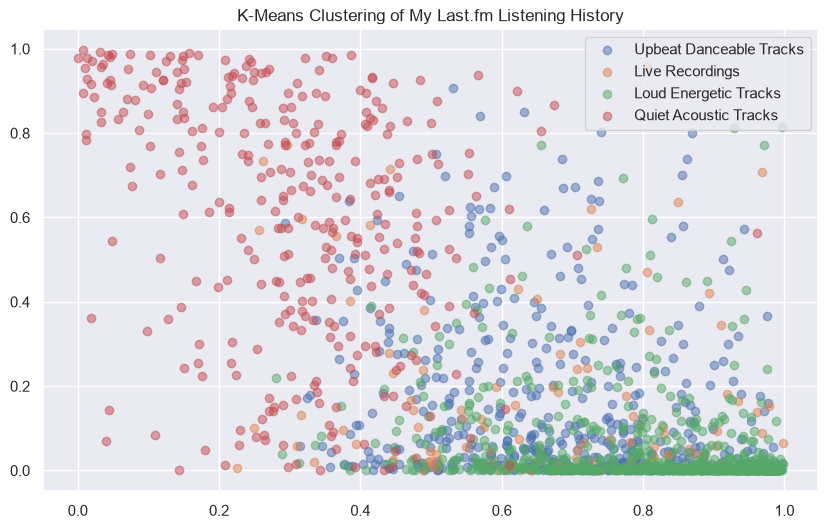

In [22]:
cluster_labels = {
    0: "Upbeat Danceable Tracks",
    1: "Live Recordings",
    2: "Loud Energetic Tracks",
    3: "Quiet Acoustic Tracks"
}

plt.figure(figsize=(10, 6))
for cluster in range(CLUSTER_COUNT):
    cluster_data = X[X['cluster'] == cluster]
    plt.scatter(cluster_data['energy'], cluster_data['acousticness'],
                label=cluster_labels[cluster], alpha=0.5)
plt.title('K-Means Clustering of My Last.fm Listening History')
plt.legend()
plt.show()

In [23]:
from sklearn.metrics import silhouette_score

silhouette_scores = silhouette_score(X_scaled, clusters)
print(f'Silhouette Score: {silhouette_scores:.4f}')

Silhouette Score: 0.1902


In [24]:
print(tracks.groupby('tod')[features].mean())

           danceability    energy   loudness  speechiness  acousticness  \
tod                                                                       
afternoon      0.447146  0.695698  -7.981579     0.066458      0.163088   
evening        0.528170  0.632305  -8.717462     0.062643      0.204778   
morning        0.433030  0.724211  -8.175647     0.083224      0.174805   
night          0.601254  0.543267 -11.499175     0.046676      0.250616   

           instrumentalness  liveness   valence  
tod                                              
afternoon          0.192488  0.188980  0.403176  
evening            0.207436  0.206944  0.462278  
morning            0.219664  0.210893  0.391403  
night              0.773759  0.219167  0.595579  


## Listening by time of day

Aggregating the same eight audio features by time of day produces a very clear pattern:

- **Night:** instrumentalness jumps to 0.77, roughly three to four times the other periods. Loudness is the lowest (-11.5) and danceability is the highest (0.60). Night listening is ambient, instrumental and quieter
- **Morning and afternoon:** higher energy (~0.70–0.72) than night, with low instrumentalness. More energetic and vocal
- **Evening:** sits in between, with slightly higher valence (0.46) than the other periods.

This matches the question asked: quieter, more atmospheric music at night, and more energetic music earlier in the day

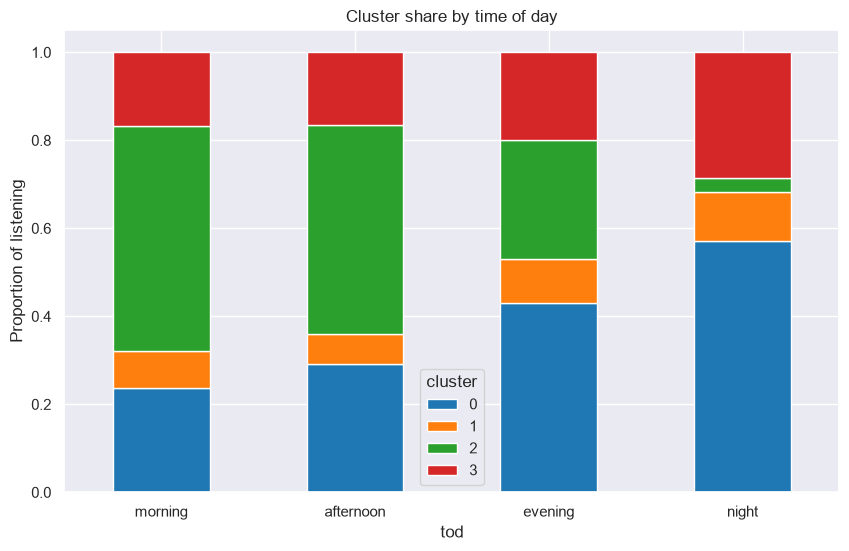

In [25]:
tod_cluster = pd.crosstab(tracks['tod'], X['cluster'], normalize='index')
tod_cluster = tod_cluster.loc[tod_order]

tod_cluster.plot(kind='bar', stacked=True, figsize=(10, 6),
                 color=['tab:blue', 'tab:orange', 'tab:green', 'tab:red'])
plt.title('Cluster share by time of day')
plt.ylabel('Proportion of listening')
plt.xticks(rotation=0)
plt.legend(title='cluster')
plt.show()